In [16]:
#THIS NOTEBOOK GENERATES RESULT PLOTS FOR THE OFFICIAL DHFUS BASELINE MODEL

import pandas as pd                                     #IMPORTS DATAFRAME HANDLING LIBRARY
import numpy as np                                      #IMPORTS NUMERICAL OPERATIONS LIBRARY
import matplotlib.pyplot as plt                         #IMPORTS LIBRARY FOR MATLAB STYLE PLOTTING

import pandas as pd
from pathlib import Path                                #IMPORTS FILE PATH HANDLING LIBRARY

print("Working directory:", Path.cwd())                                         #VERIFIES WORKING DIRECTORY AS THE SAME ONE USED BY BASELINE
df_check = pd.read_csv("dHfus_baseline_predictions.csv")
print("Columns:", df_check.columns.tolist())
print("Full path:", (Path.cwd() / "dHfus_baseline_predictions.csv").resolve())


import pandas as pd                                                             #VERIFIES THAT FUNCTION CHANGES PROPOGATED THROUGH
df = pd.read_csv("dHfus_baseline_predictions.csv")
print(df.columns.tolist())


Working directory: c:\Users\Jaco Olivier\Downloads\SCRIPSIE\Code Related\Implement
Columns: ['run_name', 'y_true', 'y_pred', 'abs_error', 'rel_error_pct']
Full path: C:\Users\Jaco Olivier\Downloads\SCRIPSIE\Code Related\Implement\dHfus_baseline_predictions.csv
['run_name', 'y_true', 'y_pred', 'abs_error', 'rel_error_pct']


(465, 5)


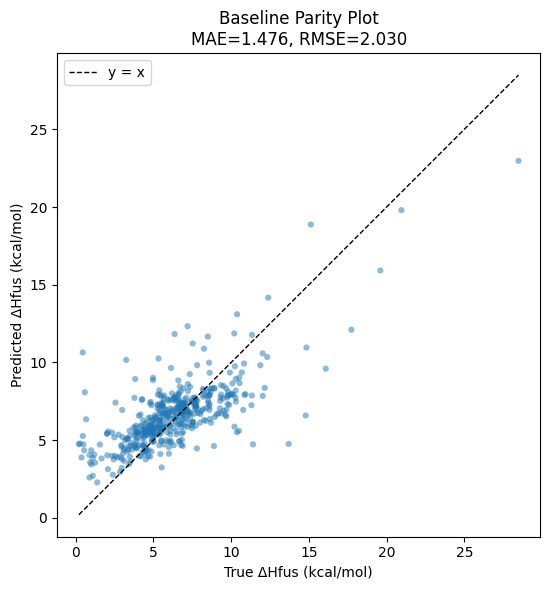

In [ ]:
predictions = pd.read_csv("dHfus_baseline_predictions.csv")    #READS SAVED PREDICTIONS FROM BASELINE CSV
print(predictions.shape)
predictions.head()

#BASELINE PARITY PLOT: MOST INTUITIVE REPRESENTATION OF ERROR
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(predictions["y_true"], predictions["y_pred"], alpha=0.5, s=20, edgecolor="none")

lims = [min(predictions["y_true"].min(), predictions["y_pred"].min()),
        max(predictions["y_true"].max(), predictions["y_pred"].max())]
ax.plot(lims, lims, "k--", linewidth=1, label="y = x")

mae = predictions["abs_error"].mean()
rmse = np.sqrt((predictions["abs_error"] ** 2).mean())

ax.set_xlabel("True ΔHfus (kcal/mol)")
ax.set_ylabel("Predicted ΔHfus (kcal/mol)")
ax.set_title(f"Baseline Parity Plot\nMAE={mae:.3f}, RMSE={rmse:.3f}")
ax.legend()
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.savefig("plots_dHfus_parity.png", dpi=150)
plt.show()
#IN THISE CASE, GENERALLY GOOD FIT WITH A FEW OUTLIERS. 

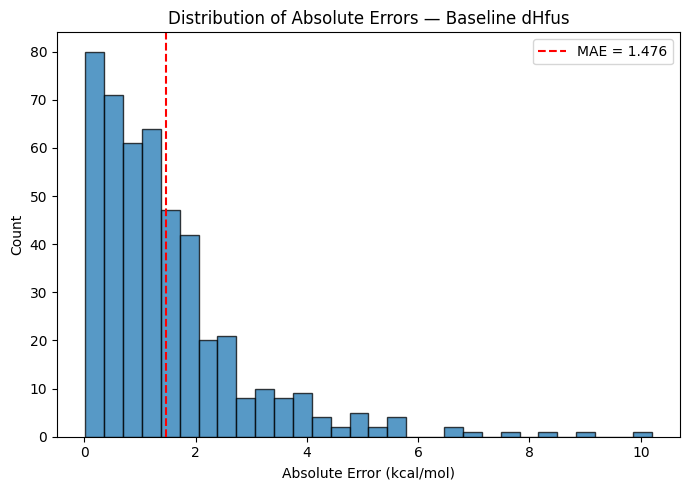

Excluding 6 molecules with |y_true| < 0.5 kcal/mol


In [18]:

#ABSOLUTE ERROR HISTOGRAM: SHOWS DISTRIBUTIONS
fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(predictions["abs_error"], bins=30, edgecolor="black", alpha=0.75)
ax.axvline(mae, color="red", linestyle="--", label=f"MAE = {mae:.3f}")
ax.set_xlabel("Absolute Error (kcal/mol)")
ax.set_ylabel("Count")
ax.set_title("Distribution of Absolute Errors — Baseline dHfus")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_abs_error_hist.png", dpi=150)
plt.show()

near_zero_threshold = 0.5  # kcal/mol
near_zero_mask = predictions["y_true"].abs() < near_zero_threshold
n_excluded = near_zero_mask.sum()
print(f"Excluding {n_excluded} molecules with |y_true| < {near_zero_threshold} kcal/mol")


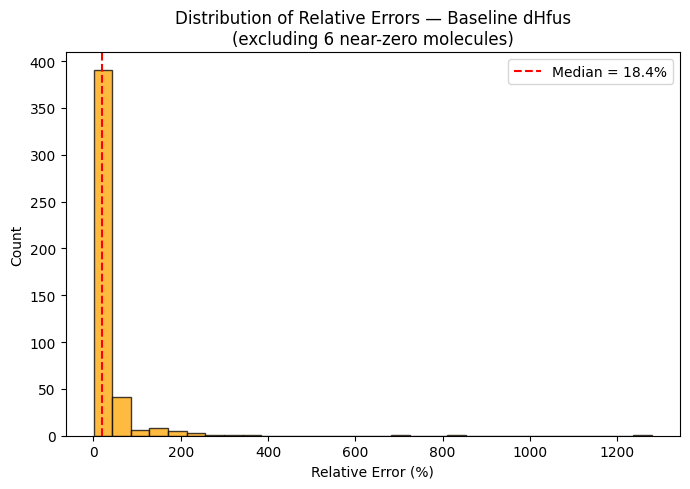

In [19]:

rel_error_filtered = predictions.loc[~near_zero_mask, "rel_error_pct"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(rel_error_filtered, bins=30, edgecolor="black", alpha=0.75, color="orange")
ax.axvline(rel_error_filtered.median(), color="red", linestyle="--",
           label=f"Median = {rel_error_filtered.median():.1f}%")
ax.set_xlabel("Relative Error (%)")
ax.set_ylabel("Count")
ax.set_title(f"Distribution of Relative Errors — Baseline dHfus\n(excluding {n_excluded} near-zero molecules)")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_rel_error_hist.png", dpi=150)
plt.show()


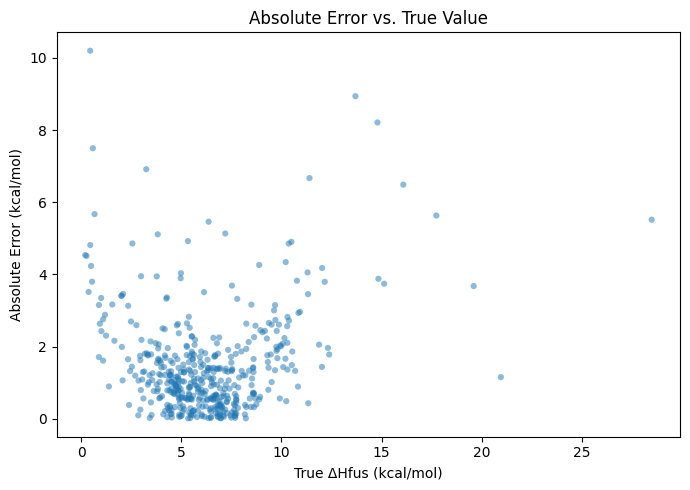

In [ ]:
#AE VS TRUE VALUE: SHOWS HOW MAGNITUDE OF TARGET EFFECTS ERROR
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(predictions["y_true"], predictions["abs_error"], alpha=0.5, s=20, edgecolor="none")
ax.set_xlabel("True ΔHfus (kcal/mol)")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Absolute Error vs. True Value")
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_true.png", dpi=150)
plt.show()


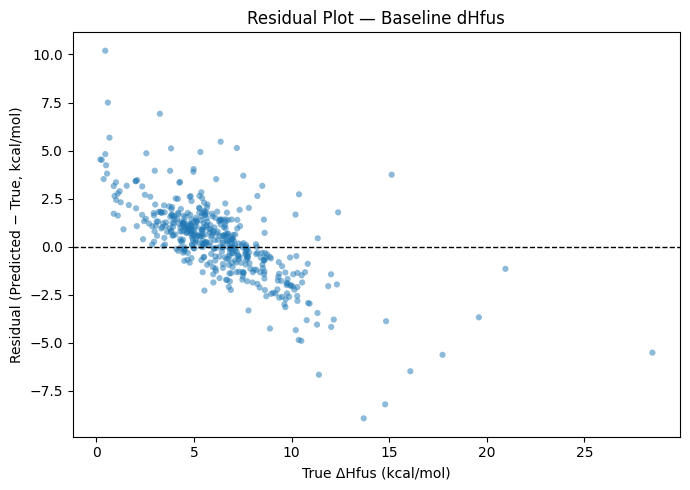

                     Metric      Value
                        MAE   1.476081
                       RMSE   2.029571
      Median Absolute Error   1.139969
  Median Relative Error (%)  18.428265
         Max Absolute Error  10.195903
     N molecules (test set) 465.000000
N excluded (near-zero true)   6.000000


run_name         dHfus_OFFICIAL_BASELINE
y_true                          0.451721
y_pred                         10.647624
abs_error                      10.195903
rel_error_pct                2257.122206
residual                       10.195903
Name: 114, dtype: object

In [ ]:
#RESIDUAL PLOT: SHOWS WHERE PREDICTIONS ARE OVER OR UNDER ESTIMATED
predictions["residual"] = predictions["y_pred"] - predictions["y_true"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(predictions["y_true"], predictions["residual"], alpha=0.5, s=20, edgecolor="none")
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("True ΔHfus (kcal/mol)")
ax.set_ylabel("Residual (Predicted − True, kcal/mol)")
ax.set_title("Residual Plot — Baseline dHfus")
plt.tight_layout()
plt.savefig("plots_dHfus_residuals.png", dpi=150)
plt.show()

summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "Median Absolute Error", "Median Relative Error (%)",
               "Max Absolute Error", "N molecules (test set)", "N excluded (near-zero true)"],
    "Value": [
        predictions["abs_error"].mean(),
        np.sqrt((predictions["abs_error"] ** 2).mean()),
        predictions["abs_error"].median(),
        rel_error_filtered.median(),
        predictions["abs_error"].max(),
        len(predictions),
        n_excluded,
    ]
})
print(summary.to_string(index=False))
summary.to_csv("dHfus_baseline_summary_stats.csv", index=False)

predictions.loc[predictions["abs_error"].idxmax()]